# Cancer Cell Classification using Machine Learning

## 1. Importing Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, recall_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

In [4]:
# Load the built-in breast cancer dataset
data = load_breast_cancer()

# Put it into a table (DataFrame)
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the answer column: 0 = Malignant, 1 = Benign
df['target'] = data.target

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Exploratory Data Analysis

In [5]:
# Check if any values are missing
print("Total missing values:", df.isnull().sum().sum())

# Count how many tumors are in each class
print("\nClass counts:")
print(df['target'].value_counts())

Total missing values: 0

Class counts:
target
1    357
0    212
Name: count, dtype: int64


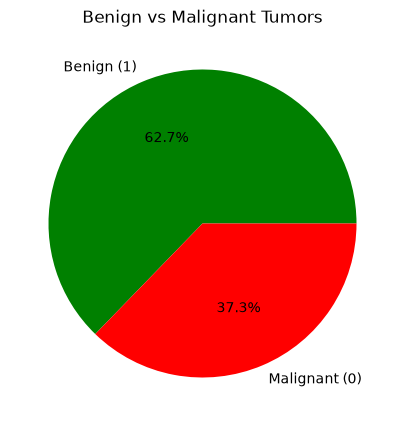

In [6]:
class_counts = df['target'].value_counts()
labels = ['Benign (1)', 'Malignant (0)']

plt.figure(figsize=(5, 5))
plt.pie(class_counts, labels=labels, autopct='%1.1f%%', colors=['green', 'red'])
plt.title("Benign vs Malignant Tumors")
plt.show()

## 4. Train-Test Split

In [7]:
# X = the 30 features (inputs), y = the answer (0 or 1)
X = df.drop('target', axis=1)
y = df['target']

# 67% for training, 33% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 381
Testing samples: 188


## 5. Feature Scaling

In [8]:
scaler = StandardScaler()

# Learn the scaling from training data, then apply it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data (don't learn from it)
X_test_scaled = scaler.transform(X_test)

print("Before scaling (first row, first 3 features):", X_train.iloc[0, :3].values)
print("After scaling  (first row, first 3 features):", X_train_scaled[0, :3].round(2))

Before scaling (first row, first 3 features): [13.11 22.54 87.02]
After scaling  (first row, first 3 features): [-0.27  0.7  -0.19]


## 6. Training Naive Bayes Model

In [9]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

print("Naive Bayes model trained!")

Naive Bayes model trained!


## 7. Predictions and Accuracy

In [10]:
# Predict on the 188 test tumors
y_pred = nb_model.predict(X_test_scaled)

print("First 10 predictions:   ", y_pred[:10])
print("First 10 actual answers:", y_test.values[:10])

accuracy = accuracy_score(y_test, y_pred)
print(f"\nNaive Bayes Accuracy: {accuracy * 100:.2f}%")

First 10 predictions:    [1 1 0 0 1 1 1 1 1 1]
First 10 actual answers: [1 1 0 0 0 1 1 1 1 1]

Naive Bayes Accuracy: 94.15%


## 8. Confusion Matrix

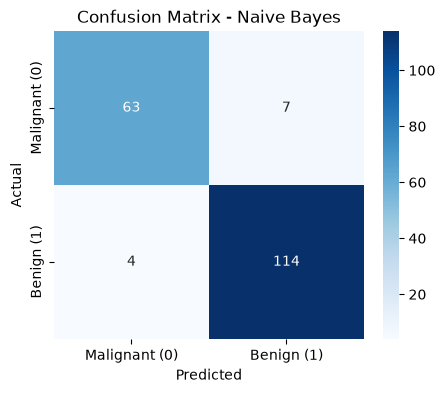

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

## 9. Classification Report

In [12]:
print(classification_report(y_test, y_pred,
                            target_names=['Malignant (0)', 'Benign (1)']))

               precision    recall  f1-score   support

Malignant (0)       0.94      0.90      0.92        70
   Benign (1)       0.94      0.97      0.95       118

     accuracy                           0.94       188
    macro avg       0.94      0.93      0.94       188
 weighted avg       0.94      0.94      0.94       188



## 10. Model Comparison

In [13]:
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, preds)
    mal_recall = recall_score(y_test, preds, pos_label=0)

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Malignant Recall (%)": round(mal_recall * 100, 2)
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy (%),Malignant Recall (%)
0,Naive Bayes,94.15,90.00
1,Logistic Regression,98.94,98.57
2,KNN (k=5),96.28,92.86


## 11. Predicting a Single Tumor

In [14]:
# Use the best model (already trained in the comparison step)
best_model = models["Logistic Regression"]

def predict_tumor(sample):
    # Turn the sample into a 1-row table with the same column names
    sample_df = pd.DataFrame([sample], columns=X.columns)

    # Scale it the same way as the training data
    sample_scaled = scaler.transform(sample_df)

    # Predict the class and the confidence
    pred = best_model.predict(sample_scaled)[0]
    confidence = best_model.predict_proba(sample_scaled)[0][pred] * 100

    label = "Malignant (Cancerous)" if pred == 0 else "Benign (Non-cancerous)"
    return label, confidence


# Test it on 5 tumors from the test set
for i in range(5):
    sample = X_test.iloc[i].values
    actual = "Malignant" if y_test.iloc[i] == 0 else "Benign"

    label, conf = predict_tumor(sample)
    print(f"Tumor {i+1}: Predicted = {label} ({conf:.1f}% confident) | Actual = {actual}")

Tumor 1: Predicted = Benign (Non-cancerous) (54.5% confident) | Actual = Benign
Tumor 2: Predicted = Benign (Non-cancerous) (99.9% confident) | Actual = Benign
Tumor 3: Predicted = Malignant (Cancerous) (100.0% confident) | Actual = Malignant
Tumor 4: Predicted = Malignant (Cancerous) (100.0% confident) | Actual = Malignant
Tumor 5: Predicted = Malignant (Cancerous) (79.0% confident) | Actual = Malignant


## 12. Conclusion
- Logistic Regression gave the best accuracy and malignant recall among the three models.
- Naive Bayes also performed well as a simple baseline model.
- In medical cases, catching every cancer case (high malignant recall) matters more than overall accuracy alone.
- This is an academic project. A real medical system would need much more data and testing.